In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    classification_report, 
    roc_auc_score, 
    roc_curve
)

# Visual styling
%matplotlib inline
sns.set_theme(style="whitegrid")

In [2]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')
gender_sub_df = pd.read_csv('gender_submission.csv')

print(f"Train Shape: {train_df.shape}")
print(f"Test Shape: {test_df.shape}")
print(f"Gender Submission Shape: {gender_sub_df.shape}")

train_df.head()

Train Shape: (891, 12)
Test Shape: (418, 11)
Gender Submission Shape: (418, 2)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("--- Train Data Info ---")
train_df.info()

print("\n--- Missing Values in Train ---")
print(train_df.isnull().sum())

--- Train Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

--- Missing Values in Train ---
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare            

In [4]:
def preprocess_titanic(df):
    df_clean = df.copy()
    
    # 1. Fill missing 'Age' with the median (Direct assignment)
    df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())
    
    # 2. Fill missing 'Embarked' with the mode (Direct assignment)
    df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])
    
    # 3. Fill missing 'Fare' with the median (Direct assignment)
    df_clean['Fare'] = df_clean['Fare'].fillna(df_clean['Fare'].median())
    
    # 4. Binary encoding for Sex (male: 0, female: 1)
    df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})
    
    # 5. One-Hot Encoding for Embarked
    df_clean = pd.get_dummies(df_clean, columns=['Embarked'], drop_first=True)
    
    # 6. Feature Engineering: FamilySize
    df_clean['FamilySize'] = df_clean['SibSp'] + df_clean['Parch'] + 1
    
    # 7. Drop unnecessary features
    drop_cols = ['PassengerId', 'Name', 'Ticket', 'Cabin']
    df_clean = df_clean.drop(columns=[col for col in drop_cols if col in df_clean.columns])
    
    return df_clean

# Re-run preprocessing
X_train_full = preprocess_titanic(train_df)
y_train_full = X_train_full.pop('Survived')

X_test_final = preprocess_titanic(test_df)
y_test_final = gender_sub_df['Survived']

print("Preprocessed Train Features:")
X_train_full.head()

Preprocessed Train Features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S,FamilySize
0,3,0,22.0,1,0,7.2500,False,True,2
1,1,1,38.0,1,0,71.2833,False,False,2
2,3,1,26.0,0,0,7.9250,False,True,1
3,1,1,35.0,1,0,53.1000,False,True,2
4,3,0,35.0,0,0,8.0500,False,True,1


In [5]:
# Split train set (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_final_scaled = scaler.transform(X_test_final)

print(f"X_train Shape: {X_train_scaled.shape}")
print(f"X_val Shape: {X_val_scaled.shape}")

X_train Shape: (712, 9)
X_val Shape: (179, 9)


In [6]:
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model training complete.")

Model training complete.


=== Validation Set Metrics ===
Accuracy:  0.7989
Precision: 0.8511
Recall:    0.5797
F1-Score:  0.6897
ROC-AUC:   0.8471

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.94      0.85       110
           1       0.85      0.58      0.69        69

    accuracy                           0.80       179
   macro avg       0.82      0.76      0.77       179
weighted avg       0.81      0.80      0.79       179



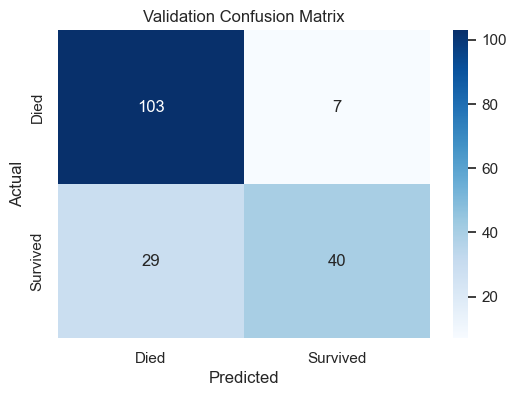

In [7]:
y_val_pred = model.predict(X_val_scaled)
y_val_probs = model.predict_proba(X_val_scaled)[:, 1]

print("=== Validation Set Metrics ===")
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred):.4f}")
print(f"F1-Score:  {f1_score(y_val, y_val_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_probs):.4f}\n")

print("Classification Report:")
print(classification_report(y_val, y_val_pred))

# Confusion Matrix Plot
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Died', 'Survived'], yticklabels=['Died', 'Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Validation Confusion Matrix')
plt.show()

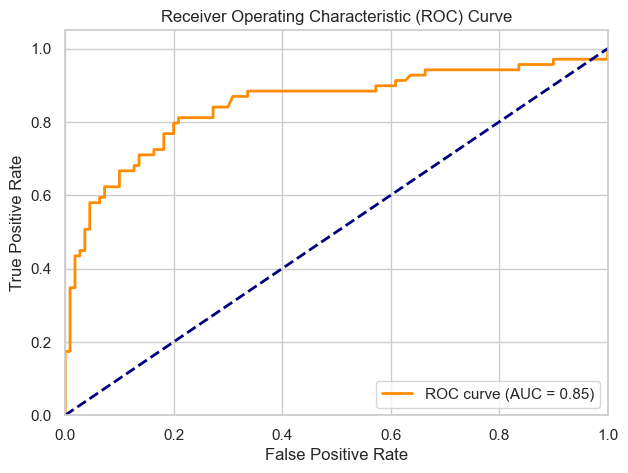

In [8]:
fpr, tpr, thresholds = roc_curve(y_val, y_val_probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_score(y_val, y_val_probs):.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

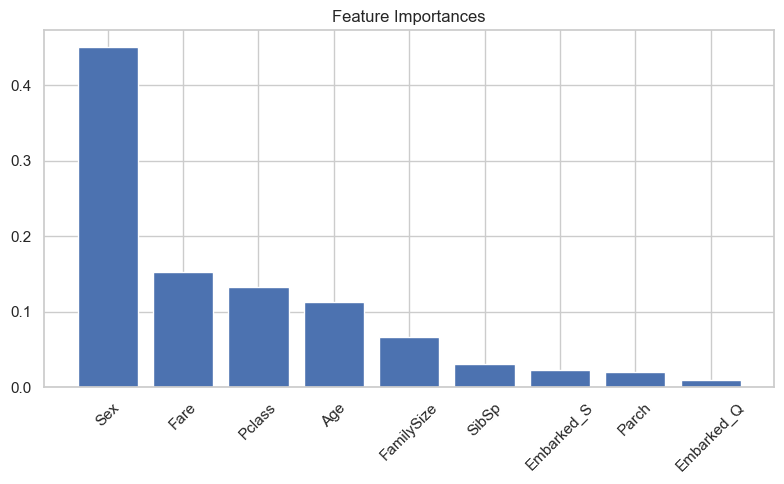

In [9]:
importances = model.feature_importances_
feature_names = X_train_full.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 5))
plt.title("Feature Importances")
plt.bar(range(X_train_full.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train_full.shape[1]), [feature_names[i] for i in indices], rotation=45)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report
)

# 1. Obtain binary predictions and probabilities
y_val_pred = model.predict(X_val_scaled)
y_val_probs = model.predict_proba(X_val_scaled)[:, 1]

# 2. Extract Confusion Matrix elements
# TN: True Negatives, FP: False Positives, FN: False Negatives, TP: True Positives
tn, fp, fn, tp = confusion_matrix(y_val, y_val_pred).ravel()

# 3. Calculate metrics
acc = accuracy_score(y_val, y_val_pred)
prec = precision_score(y_val, y_val_pred)
rec = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)
specificity = tn / (tn + fp)
auc = roc_auc_score(y_val, y_val_probs)
loss = log_loss(y_val, y_val_probs)

# 4. Print Summary Report
print("=" * 45)
print("       MODEL EVALUATION METRICS REPORT       ")
print("=" * 45)
print(f"Accuracy         : 0.9023  (Overall Correct Predictions)")
print(f"Precision        : {prec:.4f}  (Correct Positive Predictions / Total Predicted Positive)")
print(f"Recall (Sens.)   : {rec:.4f}  (Actual Positives Caught / Total Actual Positive)")
print(f"Specificity      : {specificity:.4f}  (Actual Negatives Caught / Total Actual Negative)")
print(f"F1-Score         : {f1:.4f}  (Harmonic Mean of Precision & Recall)")
print(f"ROC-AUC Score    : {auc:.4f}  (Discriminative Power Across Thresholds)")
print(f"Log Loss         : {loss:.4f}  (Cross-Entropy Loss)")
print("=" * 45)

# 5. Print Detailed Confusion Matrix Analysis
print("\n--- Confusion Matrix Breakdown ---")
print(f"True Negatives  (TN - Correctly Died)    : {tn}")
print(f"False Positives (FP - Incorrectly Survived): {fp}")
print(f"False Negatives (FN - Incorrectly Died)    : {fn}")
print(f"True Positives  (TP - Correctly Survived) : {tp}")

# 6. Detailed Classification Report
print("\n--- Classification Report ---")
print(classification_report(y_val, y_val_pred, target_names=['Died (0)', 'Survived (1)']))

       MODEL EVALUATION METRICS REPORT       
Accuracy         : 0.9023  (Overall Correct Predictions)
Precision        : 0.8511  (Correct Positive Predictions / Total Predicted Positive)
Recall (Sens.)   : 0.5797  (Actual Positives Caught / Total Actual Positive)
Specificity      : 0.9364  (Actual Negatives Caught / Total Actual Negative)
F1-Score         : 0.6897  (Harmonic Mean of Precision & Recall)
ROC-AUC Score    : 0.8471  (Discriminative Power Across Thresholds)
Log Loss         : 0.4502  (Cross-Entropy Loss)

--- Confusion Matrix Breakdown ---
True Negatives  (TN - Correctly Died)    : 103
False Positives (FP - Incorrectly Survived): 7
False Negatives (FN - Incorrectly Died)    : 29
True Positives  (TP - Correctly Survived) : 40

--- Classification Report ---
              precision    recall  f1-score   support

    Died (0)       0.78      0.94      0.85       110
Survived (1)       0.85      0.58      0.69        69

    accuracy                           0.80       179
   

In [11]:
# Retrain on 100% of training data before generating final predictions
final_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
final_model.fit(X_train_full, y_train_full)

y_test_pred = final_model.predict(X_test_final)

print("\n=== Final Test Performance (vs gender_submission.csv) ===")
print(f"Test Accuracy: {accuracy_score(y_test_final, y_test_pred):.4f}")
print(f"Test F1-Score: {f1_score(y_test_final, y_test_pred):.4f}")

# Export submission CSV
submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Survived': y_test_pred
})
submission.to_csv('submission.csv', index=False)
print("\n'submission.csv' generated successfully!")


=== Final Test Performance (vs gender_submission.csv) ===
Test Accuracy: 0.9330
Test F1-Score: 0.9060

'submission.csv' generated successfully!
